# Bài tập tổng hợp (Capstone) — Phân tích cảnh thực

Notebook chạy toàn bộ pipeline phân tích một cảnh thực, bám theo `docs/CV-project-tonghop.pdf` và các slide **Chap 01 – 13**. Mỗi bước dùng kỹ thuật của slide, **tự hiện thực lại phần cốt lõi** (`src/slides_ch09_11.py`, `src/slides_ch05_08.py`, `src/slides_ch02_04.py`) và đối chiếu với OpenCV; riêng bước phân vùng có thêm một **bộ kiểm thử có ground truth** để so sánh phương pháp bằng số.

| Yêu cầu của đề | Nội dung notebook | Slide |
|---|---|---|
| **3.1** Thu thập & tiền xử lý | resize, cân bằng ánh sáng (histogram / CLAHE), khử nhiễu (Gaussian / median / bilateral), đo chất lượng | Chap 01, 02 |
| **3.2** Hình học & cấu trúc cảnh | gradient & Canny, làm sạch biên bằng hình thái học, **Hough** đường thẳng/đường tròn (tự viết), góc Harris/Shi-Tomasi, **ước lượng homography** SIFT + RANSAC | Chap 03, 04, 06–07, 08, 09 |
| **3.3** Nội dung / đối tượng | vùng nổi bật (saliency), phân vùng: Otsu, ngưỡng thích nghi, region growing, k-means, watershed, **GrabCut/graph cut**; đánh giá IoU/Dice trên dữ liệu có ground truth | Chap 10–11 |
| **3.4** Trực quan hóa | overlay, so sánh trước/sau, bảng thời gian từng bước | — |
| Mở rộng | so sánh nhiều phương pháp, đánh giá định lượng, đo tốc độ | — |

Các slide học sâu (Chap 12–13: phân loại, phát hiện đối tượng R-CNN/YOLO) cần trọng số huấn luyện sẵn; môi trường này chạy offline nên **không** đưa vào, nhưng vai trò của chúng được nêu ở phần phân tích hạn chế (3.3).

## Setup

In [1]:
# Colab only: clone the repo so src/ is available, then cd into it.
# !git clone https://github.com/nghoang1162050/CO3057-BTL_17.git repo && %cd repo
# !pip install -q -r requirements.txt

import os, sys, time
for cand in ("src", os.path.join("..", "src")):          # works from the repo root or from notebooks/
    if os.path.isdir(cand):
        SRC_DIR = os.path.abspath(cand)
        break
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)

import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams["figure.dpi"] = 70


def show(images, titles=None, ncols=None, size=4.0, cmap="gray"):
    """Display a row/grid of images. uint8 gray images use a fixed 0-255
    window, float images are auto-scaled."""
    n = len(images)
    ncols = ncols or n
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 0.95))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles or [""] * n):
        if im.ndim == 2:
            kw = dict(vmin=0, vmax=255) if im.dtype == np.uint8 else {}
            ax.imshow(im, cmap=cmap, **kw)
        else:
            ax.imshow(im)
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

from skimage import data, img_as_ubyte
from utils import to_gray3, add_gaussian_noise
import tonghop_preprocess as prep
import tonghop_geometry as geo
import tonghop_content as content
import slides_ch02_04 as sl
import slides_ch05_08 as s58
import slides_ch09_11 as s9

print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


**Về cảnh sử dụng.** Mặc định nạp ảnh `camera` ("Cameraman") của `scikit-image`: ảnh thực ngoài trời có người chụp ảnh, chân máy và tòa nhà, nên có cả cấu trúc hình học rõ (chân máy, đường mái nhà) lẫn một đối tượng nổi bật. Có thể đặt ảnh/khung hình của nhóm vào `data/tonghop_scene/` — pipeline tự dùng ảnh đó (xem README trong thư mục). Vì ảnh thực **không có ground truth** cho phân vùng, phần 3.3 bổ sung thêm hai cảnh *tổng hợp có mask thật* để đánh giá bằng số; các nhận xét về ảnh thực chỉ mang tính định tính.

---
## 3.1 — Thu thập và tiền xử lý dữ liệu

### 3.1.1 Chuẩn hóa kích thước và ánh sáng (Chap 01 s.9; Chap 02 s.2–14)

Ảnh được thu nhỏ để cạnh dài ≤ 640 px (giữ ngưỡng Hough/GrabCut nhất quán, giảm dữ liệu — ý của slide "độ phân giải thấp ⇒ ít dữ liệu"). Ảnh thực có **dải động** lớn hơn dải 0–255 nên cần cân bằng sáng. Cân bằng histogram *toàn cục* áp một ánh xạ $T(r)$ cho cả ảnh, dễ khuếch đại nhiễu ở vùng phẳng; **CLAHE** làm theo từng ô (tile) với giới hạn độ tương phản (clip limit) nên cục bộ hơn.

[Tonghop] No scene photo found -- using the scikit-image 'camera' sample


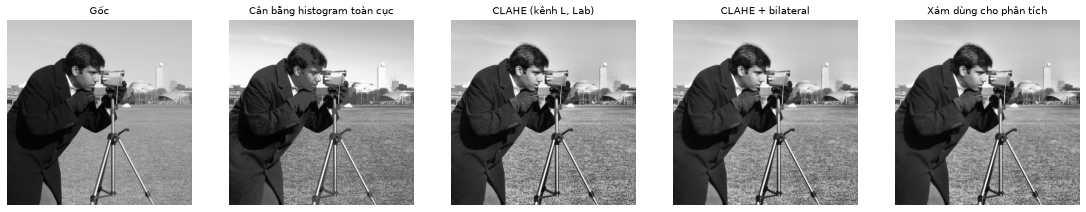

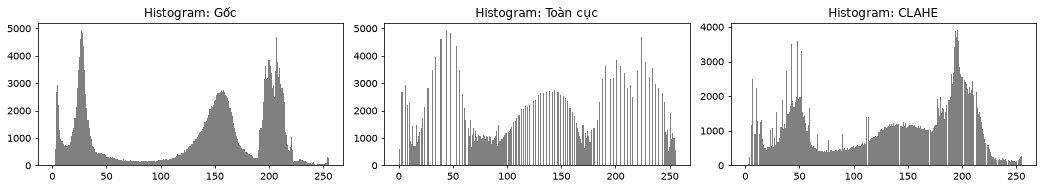

              std toàn ảnh   tương phản cục bộ (std 15x15)  std vùng phẳng (trời)
gốc                  73.64                           14.90                   2.89
toàn cục             73.67                           19.22                   7.61
CLAHE                68.86                           22.32                   6.80


In [2]:
scene = prep.load_scene()
pre = prep.preprocess(scene)
gray0 = cv2.cvtColor(pre["original"], cv2.COLOR_RGB2GRAY)

glob_eq = sl.hist_equalize(gray0)
clahe = cv2.cvtColor(pre["normalized"], cv2.COLOR_RGB2GRAY)
sky = (slice(0, 60), slice(300, 500))              # vùng phẳng (trời) -> đo khuếch đại nhiễu
show([pre["original"], to_gray3(glob_eq), pre["normalized"], pre["denoised"], to_gray3(pre["gray"])],
     ["Gốc", "Cân bằng histogram toàn cục", "CLAHE (kênh L, Lab)", "CLAHE + bilateral", "Xám dùng cho phân tích"], size=3.2)

fig, ax = plt.subplots(1, 3, figsize=(15, 2.8))
for a, im, t in zip(ax, [gray0, glob_eq, clahe], ["Gốc", "Toàn cục", "CLAHE"]):
    a.bar(np.arange(256), sl.histogram(im), width=1.0, color="gray"); a.set_title(f"Histogram: {t}")
plt.tight_layout(); plt.show()
def local_contrast(im, k=15):
    f = im.astype(np.float32); m = cv2.blur(f, (k, k)); return float(np.sqrt(np.maximum(cv2.blur(f * f, (k, k)) - m * m, 0)).mean())
print(f"{'':12s} {'std toàn ảnh':>13s} {'tương phản cục bộ (std 15x15)':>31s} {'std vùng phẳng (trời)':>22s}")
for name, im in [("gốc", gray0), ("toàn cục", glob_eq), ("CLAHE", clahe)]:
    print(f"{name:12s} {im.std():13.2f} {local_contrast(im):31.2f} {im[sky].std():22.2f}")

### 3.1.2 Khử nhiễu: Gaussian vs median vs bilateral (Chap 02 s.45–67)

Trước phát hiện biên/góc cần khử nhiễu nhưng **không được làm mờ biên**. Ta thêm nhiễu Gauss vào ảnh (biết ảnh sạch) rồi đo: **PSNR** so với ảnh sạch, và **F1 của biên Canny** (biên của ảnh đã khử nhiễu so với biên của ảnh sạch, dung sai 1 px) — chỉ số trực tiếp cho mục đích "chuẩn bị cho 3.2".

phương pháp               PSNR (dB)   F1 biên  precision   recall  #px biên
không khử nhiễu               22.29     0.803      0.675    0.989     60307
Gaussian 5x5 (s=1.5)          23.14     0.506      0.996    0.339     11787
median 5x5                    22.62     0.538      0.991    0.369     12759
bilateral (d=7)               28.08     0.939      0.980    0.902     35999
bilateral (d=9, s=75)         28.89     0.873      0.994    0.778     29951


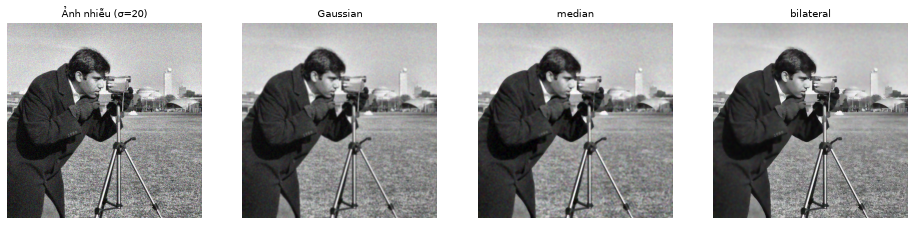

In [3]:
clean = pre["normalized"]
noisy = add_gaussian_noise(clean, sigma=20)
cands = {
    "không khử nhiễu": noisy,
    "Gaussian 5x5 (s=1.5)": cv2.GaussianBlur(noisy, (5, 5), 1.5),
    "median 5x5": cv2.medianBlur(noisy, 5),
    "bilateral (d=7)": prep.denoise(noisy, 7, 50, 50),
    "bilateral (d=9, s=75)": prep.denoise(noisy, 9, 75, 75),
}
ref_edges = cv2.Canny(cv2.cvtColor(clean, cv2.COLOR_RGB2GRAY), 80, 180) > 0
def edge_f1(im, tol=1):
    e = cv2.Canny(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), 80, 180) > 0
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    prec = (e & (cv2.dilate(ref_edges.astype(np.uint8), k) > 0)).sum() / max(e.sum(), 1)
    rec = (ref_edges & (cv2.dilate(e.astype(np.uint8), k) > 0)).sum() / max(ref_edges.sum(), 1)
    return float(2 * prec * rec / max(prec + rec, 1e-9)), float(prec), float(rec), int(e.sum())
print(f"{'phương pháp':24s} {'PSNR (dB)':>10s} {'F1 biên':>9s} {'precision':>10s} {'recall':>8s} {'#px biên':>9s}")
for name, im in cands.items():
    f1, p, r, n = edge_f1(im)
    print(f"{name:24s} {cv2.PSNR(im, clean):10.2f} {f1:9.3f} {p:10.3f} {r:8.3f} {n:9d}")
show([noisy, cands["Gaussian 5x5 (s=1.5)"], cands["median 5x5"], cands["bilateral (d=9, s=75)"]],
     ["Ảnh nhiễu (σ=20)", "Gaussian", "median", "bilateral"], size=3.4)

**Nhận xét 3.1.**
- *Ánh sáng.* CLAHE nâng **tương phản cục bộ** nhiều nhất (14.9 → 22.3, so với 19.2 của cân bằng toàn cục) trong khi std toàn ảnh gần như không đổi (73.6 → 68.9): nó làm rõ chi tiết cục bộ chứ không kéo giãn cả dải xám. Nhưng nó **vẫn khuếch đại nhiễu ở vùng phẳng** (std vùng trời 2.9 → 6.8, gần như cân bằng toàn cục: 7.6) vì clip limit chỉ giảm nhẹ hiệu ứng này — đó là lý do khử nhiễu phải đi *sau* CLAHE.
- *Khử nhiễu.* Bảng cho thấy PSNR không đủ để chọn: Gaussian và median có precision biên rất cao (≈ 0.99) nhưng **recall chỉ ≈ 0.34–0.37** — mất khoảng hai phần ba biên thật (một phần do làm mờ hạ gradient dưới ngưỡng Canny cố định 80/180, cũng là lý do ngưỡng Canny phải chỉnh theo bước tiền xử lý). **Bilateral** cho PSNR cao nhất (28 dB, so với ≈ 22–23 dB) và F1 biên cao nhất (0.94 với d=7), vì trọng số theo cả khoảng cách lẫn độ chênh cường độ nên chỉ làm mịn nơi phẳng. Tăng mạnh hơn (d=9, σ=75) PSNR nhích lên nhưng F1 giảm (0.87) — làm mịn quá tay lại hại biên. Ảnh `camera` gốc khá sạch nên phép thử dùng nhiễu nhân tạo σ=20.

---
## 3.2 — Phân tích hình học và cấu trúc cảnh

Đề yêu cầu ít nhất một hướng; ta làm bốn: **biên**, **đường thẳng/đường tròn (Hough)**, **góc**, và **ước lượng phép biến đổi** giữa hai ảnh cùng cảnh.

### 3.2.1 Biên: gradient → Canny (Chap 03 s.5–14; Chap 09 s.3–9)

Biên = nơi gradient lớn. Chỉ ngưỡng độ lớn gradient cho **biên dày và đứt đoạn** ("missing edge continuity, many spurious edges", Chap 09 s.3). **Canny** thêm *làm mịn* (DoG), *non-maximum suppression* (làm mảnh biên dọc hướng gradient) và *hysteresis* (ngưỡng kép, chỉ giữ biên yếu nếu nối với biên mạnh).

Chỉ ngưỡng gradient (top 10%): 26215 px | Canny: 33449 px
Số thành phần liên thông: ngưỡng gradient = 450 | Canny = 1103
Bề dày trung bình của nét biên: ngưỡng gradient = 3.3 px | Canny = 1.2 px


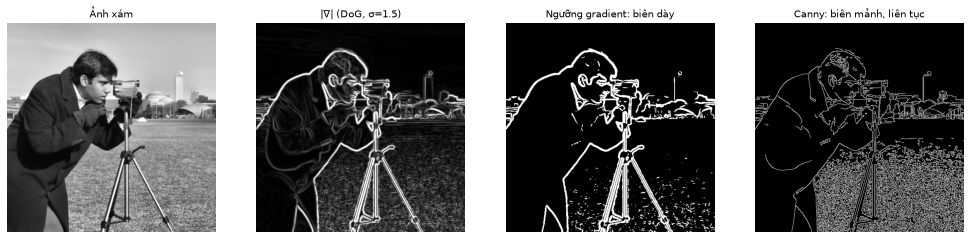

In [4]:
g = pre["gray"]
mag, theta = sl.gradient(g, sigma=1.5)                        # đạo hàm Gaussian (tự viết)
thr_only = (mag > np.percentile(mag, 90)).astype(np.uint8) * 255
canny = geo.detect_edges(g)
print(f"Chỉ ngưỡng gradient (top 10%): {int((thr_only > 0).sum())} px | Canny: {int((canny > 0).sum())} px")
n_cc = lambda m: cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=8)[0] - 1
print(f"Số thành phần liên thông: ngưỡng gradient = {n_cc(thr_only)} | Canny = {n_cc(canny)}")
from skimage.morphology import skeletonize
thickness = lambda m: float((m > 0).sum() / max(skeletonize(m > 0).sum(), 1))        # diện tích / độ dài xương = bề dày trung bình (px)
print(f"Bề dày trung bình của nét biên: ngưỡng gradient = {thickness(thr_only):.1f} px | Canny = {thickness(canny):.1f} px")
show([g, np.clip(mag / mag.max() * 255 * 2, 0, 255).astype(np.uint8), thr_only, canny],
     ["Ảnh xám", "|∇| (DoG, σ=1.5)", "Ngưỡng gradient: biên dày", "Canny: biên mảnh, liên tục"], size=3.6)

### 3.2.2 Làm sạch biên bằng hình thái học (Chap 09 s.9; Chap 06–07)

Ảnh biên "đứt đoạn, nhiễu": **closing** ($A\bullet B=(A\oplus B)\ominus B$) nối các khe hẹp và lấp lỗ nhỏ; **opening** ($A\circ B=(A\ominus B)\oplus B$) xóa các nhánh/đốm nhỏ. Ta hiện thực erosion/dilation từ định nghĩa (tập hợp các điểm mà phần tử cấu trúc $B$ nằm trọn trong / chạm vào $A$) và đối chiếu với OpenCV.

Số pixel khác OpenCV (tự viết vs cv2): {'erode': 0, 'dilate': 0, 'open': 0, 'close': 0}
Số thành phần liên thông:  Canny = 1103 | sau closing(r=2) = 23 | sau opening = 94


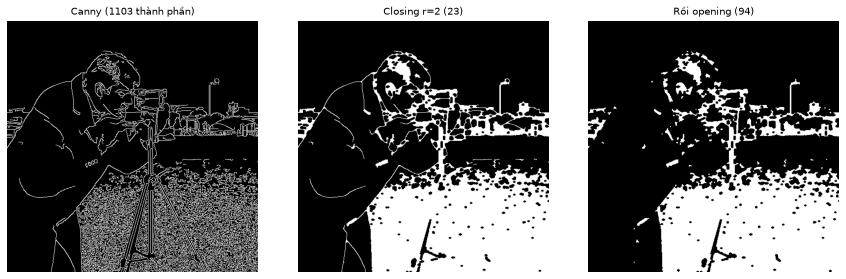

In [5]:
se = s9.disk(1)
mine = {"erode": s9.erode(canny, se), "dilate": s9.dilate(canny, se), "open": s9.opening(canny, se), "close": s9.closing(canny, se)}
ref = {"erode": cv2.erode(canny, se), "dilate": cv2.dilate(canny, se),
       "open": cv2.morphologyEx(canny, cv2.MORPH_OPEN, se), "close": cv2.morphologyEx(canny, cv2.MORPH_CLOSE, se)}
print("Số pixel khác OpenCV (tự viết vs cv2):", {k: int((mine[k] != ref[k]).sum()) for k in mine})
closed = s9.closing(canny, s9.disk(2))
opened = s9.opening(closed, np.ones((2, 2), np.uint8))
print(f"Số thành phần liên thông:  Canny = {n_cc(canny)} | sau closing(r=2) = {n_cc(closed)} | sau opening = {n_cc(opened)}")
show([canny, closed, opened], [f"Canny ({n_cc(canny)} thành phần)", f"Closing r=2 ({n_cc(closed)})", f"Rồi opening ({n_cc(opened)})"], size=4.2)

### 3.2.2b Hình thái học mở rộng: các thuật toán cơ bản và reconstruction (Chap 06–07 s.26–106)

Ngoài erode/dilate/opening/closing, slide còn có các thuật toán xây từ chúng (`src/slides_ch06_07.py`, tự hiện thực bằng numpy): **hit-or-miss**, **trích biên** $\beta(A)=A-(A\ominus B)$, **lấp lỗ**, **thành phần liên thông** (giãn có điều kiện $X_k=(X_{k-1}\oplus B)\cap A$), **thinning**, **xương (skeleton)** của Lantuéjoul, và **morphological reconstruction** (opening by reconstruction, border clearing); với ảnh xám có gradient hình thái, top-hat/bottom-hat và granulometry. Quy ước ở đây: ngoài ảnh là nền (khác `erode` kiểu OpenCV ở trên).

Trước hết đối chiếu từng hàm với thư viện chuẩn trên một mặt nạ ngẫu nhiên, rồi dùng chúng trên hình ngựa (`skimage.data.horse`).

In [6]:
import slides_ch06_07 as s67
from scipy import ndimage as ndi
from skimage import morphology as skmo
from skimage.segmentation import clear_border as sk_clear_border

rng = np.random.default_rng(0)
rnd = ndi.gaussian_filter(rng.random((120, 160)), 3) > 0.52
disk2 = s9.disk(2) > 0
lab_ref, n_ref = ndi.label(rnd, np.ones((3, 3)))
fimg = ndi.gaussian_filter(rng.random((100, 120)), 2) * 255
inner = lambda x: x[5:-5, 5:-5]
checks = {
    "erode / dilate (nền ngoài ảnh)": (s67.erode_b(rnd, disk2) == ndi.binary_erosion(rnd, disk2, border_value=0)).all() and (s67.dilate_b(rnd, disk2) == ndi.binary_dilation(rnd, disk2)).all(),
    "trích biên": (s67.boundary(rnd) == (rnd & ~ndi.binary_erosion(rnd, np.ones((3, 3)), border_value=0))).all(),
    "lấp lỗ (reconstruction) vs scipy": (s67.fill_holes(rnd) == ndi.binary_fill_holes(rnd)).all(),
    f"thành phần liên thông ({n_ref}) vs scipy": s67.label_components(rnd)[1] == n_ref,
    "border clearing vs skimage": (s67.clear_border(rnd) == (sk_clear_border(lab_ref) > 0)).all(),
    "reconstruction by dilation vs skimage": (s67.reconstruct_dilation(ndi.binary_erosion(rnd, np.ones((5, 5))), rnd) == (skmo.reconstruction(ndi.binary_erosion(rnd, np.ones((5, 5))).astype(np.uint8), rnd.astype(np.uint8), method="dilation", footprint=np.ones((3, 3))) > 0)).all(),
    "xám: erode/dilate vs OpenCV": np.allclose(inner(s67.gray_erode(fimg, disk2)), inner(cv2.erode(fimg.astype(np.float32), disk2.astype(np.uint8)))) and np.allclose(inner(s67.gray_dilate(fimg, disk2)), inner(cv2.dilate(fimg.astype(np.float32), disk2.astype(np.uint8)))),
    "xám: top-hat vs OpenCV": np.allclose(inner(s67.top_hat(fimg, disk2)), inner(cv2.morphologyEx(fimg.astype(np.float32), cv2.MORPH_TOPHAT, disk2.astype(np.uint8))), atol=1e-3),
}
for k, v in checks.items(): print(f"{'OK ' if v else 'SAI'}  {k}")

OK   erode / dilate (nền ngoài ảnh)
OK   trích biên
OK   lấp lỗ (reconstruction) vs scipy
OK   thành phần liên thông (47) vs scipy
OK   border clearing vs skimage
OK   reconstruction by dilation vs skimage
OK   xám: erode/dilate vs OpenCV
OK   xám: top-hat vs OpenCV


Lấp lỗ tự động: thêm 246 pixel; chỉ lấp lỗ có hạt giống: thêm 144 pixel
Xương Lantuéjoul: 1365 pixel (3.1% diện tích), 57 tập con; dựng lại từ xương == hình gốc: True
Thinning: 1685 pixel, số thành phần liên thông 1 (gốc 1)
Opening thường: IoU với hình sạch 0.998 | opening by reconstruction: 1.000


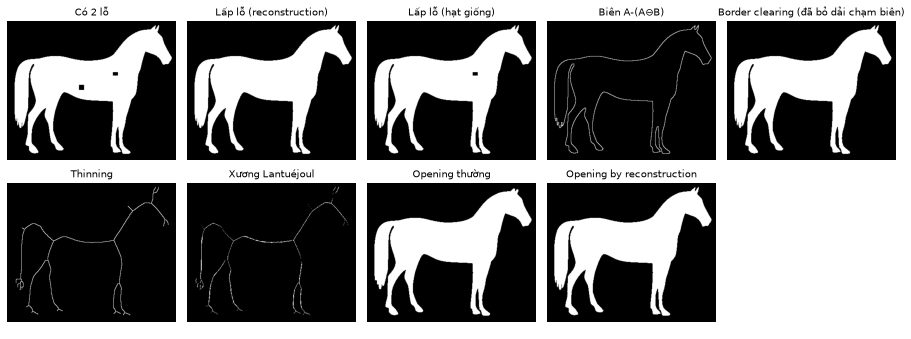

In [7]:
horse = ~data.horse()                                            # đối tượng nhị phân
holes = horse.copy(); holes[150:162, 170:182] = False; holes[120:128, 250:262] = False      # đục 2 lỗ để thử lấp
filled = s67.fill_holes(holes)
seeds = np.zeros_like(holes); seeds[155, 175] = True
filled_seed = s67.fill_holes_from_seeds(holes, seeds)           # theo slide 30-31: chỉ lấp lỗ có hạt giống
touch = horse.copy(); touch[:, :6] = True; touch[:6, :] = True    # thêm vật chạm biên
cleared = s67.clear_border(touch)
thin = s67.thinning(horse)
skel, subs = s67.skeleton_lantuejoul(horse)
rebuilt = s67.reconstruct_from_skeleton(subs)
noise = horse | (rng.random(horse.shape) > 0.995)                # thêm đốm nhiễu
open_plain = s67.opening_b(noise, s9.disk(2) > 0)
open_rec = s67.opening_by_reconstruction(noise, s9.disk(2) > 0)
print(f"Lấp lỗ tự động: thêm {int(filled.sum() - holes.sum())} pixel; chỉ lấp lỗ có hạt giống: thêm {int(filled_seed.sum() - holes.sum())} pixel")
print(f"Xương Lantuéjoul: {int(skel.sum())} pixel ({100 * skel.sum() / horse.sum():.1f}% diện tích), {len(subs)} tập con; dựng lại từ xương == hình gốc: {bool((rebuilt == horse).all())}")
print(f"Thinning: {int(thin.sum())} pixel, số thành phần liên thông {ndi.label(thin, np.ones((3, 3)))[1]} (gốc {ndi.label(horse, np.ones((3, 3)))[1]})")
print(f"Opening thường: IoU với hình sạch {s9.iou(open_plain * 255, horse * 255):.3f} | opening by reconstruction: {s9.iou(open_rec * 255, horse * 255):.3f}")
show([holes, filled, filled_seed, s67.boundary(horse), cleared, thin, skel, open_plain, open_rec],
     ["Có 2 lỗ", "Lấp lỗ (reconstruction)", "Lấp lỗ (hạt giống)", "Biên A-(A⊖B)", "Border clearing (đã bỏ dải chạm biên)", "Thinning", "Xương Lantuéjoul", "Opening thường", "Opening by reconstruction"], ncols=5, size=2.6)

Otsu toàn cục trên ảnh sáng không đều: 0.30 diện tích là đối tượng | sau top-hat (SE đĩa bán kính 25): 0.25


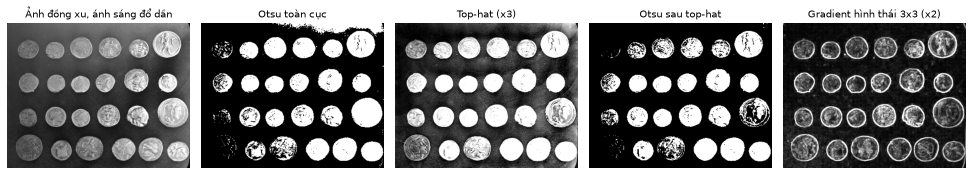

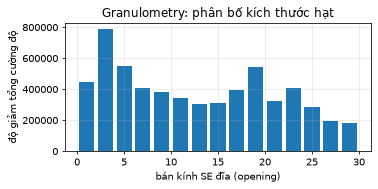

Bán kính có độ giảm lớn nhất: 3


In [8]:
coins = img_as_ubyte(data.coins())
uneven = np.clip(coins.astype(np.float32) * (0.55 + 0.9 * np.linspace(0, 1, coins.shape[1])[None, :]), 0, 255).astype(np.uint8)   # ánh sáng không đều
se_big = s9.disk(25)
th = s67.top_hat(uneven.astype(np.float64), se_big > 0)
glob = ((uneven > s9.otsu_threshold(uneven)) * 255).astype(np.uint8)
tophat_bin = ((th > s9.otsu_threshold(np.clip(th, 0, 255).astype(np.uint8))) * 255).astype(np.uint8)
mgrad = s67.morph_gradient(coins.astype(np.float64), np.ones((3, 3), bool))
radii = list(range(1, 31, 2))
areas, drop = s67.granulometry(coins.astype(np.float64), radii)
print(f"Otsu toàn cục trên ảnh sáng không đều: {(glob > 0).mean():.2f} diện tích là đối tượng | sau top-hat (SE đĩa bán kính 25): {(tophat_bin > 0).mean():.2f}")
show([uneven, glob, np.clip(th * 3, 0, 255).astype(np.uint8), tophat_bin, np.clip(mgrad * 2, 0, 255).astype(np.uint8)],
     ["Ảnh đồng xu, ánh sáng đổ dần", "Otsu toàn cục", "Top-hat (x3)", "Otsu sau top-hat", "Gradient hình thái 3x3 (x2)"], ncols=5, size=2.8)
fig, ax = plt.subplots(figsize=(5.5, 2.8)); ax.bar(radii, drop[:len(radii)], width=1.6); ax.set_xlabel("bán kính SE đĩa (opening)"); ax.set_ylabel("độ giảm tổng cường độ")
ax.set_title("Granulometry: phân bố kích thước hạt"); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("Bán kính có độ giảm lớn nhất:", radii[int(np.argmax(drop[:len(radii)]))])

**Nhận xét (từ số và hình ở trên).** Cả 8 hàm tự hiện thực khớp thư viện chuẩn trên mặt nạ thử. Với hình ngựa: dựng lại từ các tập con của xương cho đúng hình gốc (tính chất của biểu diễn Lantuéjoul, slide 52), nhưng chính tập pixel xương chỉ chiếm 3.1% diện tích và trong hình **bị đứt thành nhiều đoạn**, trong khi thinning cho đường mảnh nối liền (1 thành phần liên thông, như hình gốc). Lấp lỗ bằng reconstruction lấp cả hai lỗ đã đục, còn phiên bản có hạt giống chỉ lấp lỗ được gieo hạt (slide 30–31). Opening by reconstruction trả lại đúng hình sạch (IoU 1.000) còn opening thường chỉ đạt 0.998: chênh lệch nhỏ vì nhiễu thêm vào là đốm lẻ, nên ví dụ này chưa cho thấy khác biệt lớn. Trên ảnh đồng xu sáng không đều, top-hat loại được vùng nền sáng ở góc phải trên mà Otsu toàn cục gán nhầm là đối tượng (diện tích đối tượng 0.30 xuống 0.25), nhưng cũng làm vỡ mặt một số đồng xu sáng thành các mảng; vì vậy đây chỉ là đánh đổi quan sát được trên một ảnh, chưa chấm bằng ground truth. Granulometry in ra bán kính có độ giảm lớn nhất, chưa đối chiếu với kích thước thực của đồng xu.

### 3.2.3 Hough: biên → đường thẳng (Chap 09 s.15–26)

Khớp trực tiếp một đường bằng bình phương tối thiểu thất bại khi có **nhiễu ngoại lai, dữ liệu thiếu, nhiều mô hình** (s.16). Hough cho mỗi điểm biên **bỏ phiếu** cho mọi đường đi qua nó; với tham số hóa $\rho=x\cos\theta+y\sin\theta$ mỗi điểm vẽ một đường sin trong không gian $(\rho,\theta)$, các đường thẳng thật là **đỉnh** của mảng tích lũy. Biên không cần liên tục, vật không cần thấy hết.

Hough tự viết: 12 đỉnh trong 23 ms; số phiếu: 207, 203, 202, 191, 190, 184, 177, 177, 176, 175, 173, 172
Góc θ (độ) 6 đỉnh mạnh nhất, tự viết: [-45, -45, -45, -28, 0, 0]
Góc θ (độ), cv2.HoughLines (6 đường đầu): [-45, -45, -45, -28, 0, 0]


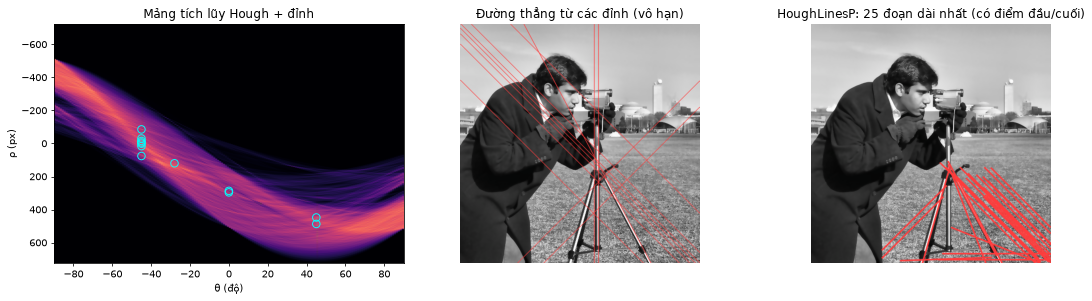

In [9]:
t0 = time.perf_counter()
acc, rhos, thetas = s9.hough_lines_accumulator(canny, theta_step_deg=1.0, rho_step=1.0)
peaks = s9.hough_peaks(acc, n_peaks=12, rel_thresh=0.45, nms=11)
t_mine = time.perf_counter() - t0
overlay = s9.draw_hough_lines(pre["denoised"], peaks, rhos, thetas)
print(f"Hough tự viết: {len(peaks)} đỉnh trong {t_mine * 1000:.0f} ms; số phiếu: " + ", ".join(str(v) for _, _, v in peaks))

# Đối chiếu cv2.HoughLines (cùng độ phân giải rho/theta, cùng ngưỡng phiếu) -- góc của các đỉnh mạnh nhất có trùng nhau không?
thr = int(0.45 * acc.max())
cv_lines = cv2.HoughLines(canny, 1, np.pi / 180, thr)
mine_angles = sorted(np.round(np.degrees(thetas[c]), 0).astype(int).tolist() for _, c, _ in peaks[:6])
print("Góc θ (độ) 6 đỉnh mạnh nhất, tự viết:", mine_angles)
if cv_lines is not None:
    print("Góc θ (độ), cv2.HoughLines (6 đường đầu):", sorted(np.round(np.degrees(cv_lines[:6, 0, 1]) - np.where(cv_lines[:6, 0, 1] > np.pi / 2, 180, 0)).astype(int).tolist()))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].imshow(acc, aspect="auto", cmap="magma", extent=[-90, 90, rhos[-1], rhos[0]]); ax[0].set_xlabel("θ (độ)"); ax[0].set_ylabel("ρ (px)")
ax[0].scatter([np.degrees(thetas[c]) for _, c, _ in peaks], [rhos[r] for r, _, _ in peaks], s=60, facecolors="none", edgecolors="cyan"); ax[0].set_title("Mảng tích lũy Hough + đỉnh")
ax[1].imshow(overlay); ax[1].axis("off"); ax[1].set_title("Đường thẳng từ các đỉnh (vô hạn)")
lines = geo.detect_lines(canny); ax[2].imshow(geo.draw_geometry(pre["denoised"], lines, np.empty((0, 2)))); ax[2].axis("off"); ax[2].set_title(f"HoughLinesP: {len(lines)} đoạn dài nhất (có điểm đầu/cuối)")
plt.tight_layout(); plt.show()

**Độ nhạy của Hough (slide 24–26).** Hai thí nghiệm: (i) *nhiễu vị trí* — dịch ngẫu nhiên các điểm biên làm phiếu loãng ra nhiều ô: số phiếu của đỉnh mạnh nhất giảm; (ii) *clutter* — thêm điểm ngẫu nhiên làm tăng số ô đạt ngưỡng giả. Kích thước ô (bước θ, ρ) cũng là đánh đổi: ô quá lớn gộp các đường khác nhau, quá nhỏ thì nhiễu làm mất đỉnh.

In [10]:
rng = np.random.default_rng(0)
ys, xs = np.nonzero(canny); h_, w_ = canny.shape
acc0, _, _ = s9.hough_lines_accumulator(canny)
top = s9.hough_peaks(acc0, n_peaks=6, rel_thresh=0.45, nms=11)               # 6 đường "thật" của ảnh gốc
weakest = min(v for _, _, v in top)
def local_max(a, r, c, k=3): return int(a[max(r - k, 0):r + k + 1, max(c - k, 0):c + k + 1].max())
def trial(jitter=0.0, clutter=0):
    px = np.clip(np.round(xs + rng.normal(0, jitter, xs.size)), 0, w_ - 1).astype(int) if jitter else xs
    py = np.clip(np.round(ys + rng.normal(0, jitter, ys.size)), 0, h_ - 1).astype(int) if jitter else ys
    img = np.zeros_like(canny); img[py, px] = 255
    if clutter: img[rng.integers(0, h_, clutter), rng.integers(0, w_, clutter)] = 255
    a, _, _ = s9.hough_lines_accumulator(img)
    kept = np.mean([local_max(a, r, c) / v for r, c, v in top])                     # phiếu còn lại tại 6 đỉnh thật (tỷ lệ so với gốc)
    n_peaks = sum(1 for _, _, v in s9.hough_peaks(a, n_peaks=10000, rel_thresh=0.0, nms=11) if v >= 0.9 * weakest)
    return kept, n_peaks
print(f"{'thí nghiệm':24s} {'phiếu còn lại ở 6 đỉnh thật':>28s} {'số đỉnh ≥ 90% đỉnh yếu nhất của 6 đỉnh thật':>46s}")
for lab, kw in [("không nhiễu", {}), ("jitter vị trí σ=1 px", dict(jitter=1)), ("jitter σ=2 px", dict(jitter=2)), ("jitter σ=4 px", dict(jitter=4)),
                ("+ 3000 điểm clutter", dict(clutter=3000)), ("+ 15000 điểm clutter", dict(clutter=15000))]:
    kept, n = trial(**kw)
    print(f"{lab:24s} {kept * 100:27.0f}% {n:46d}")

thí nghiệm                phiếu còn lại ở 6 đỉnh thật    số đỉnh ≥ 90% đỉnh yếu nhất của 6 đỉnh thật
không nhiễu                                      100%                                             30
jitter vị trí σ=1 px                              70%                                              1
jitter σ=2 px                                     69%                                              1
jitter σ=4 px                                     69%                                              3
+ 3000 điểm clutter                              104%                                             51


+ 15000 điểm clutter                             115%                                            131


**Kiểm chứng Hough bằng dữ liệu có đáp án.** Cụm đỉnh ±45° ở ảnh Cameraman đáng ngờ. Giả thuyết: số phiếu thô tỷ lệ với **độ dài dây cung** của đường trong khung ảnh, nên với bản đồ biên dày đặc (texture), các đường chéo của ảnh vuông — dây cung dài nhất — luôn thắng, bất kể có cấu trúc hay không. Hai phép thử: (i) **ảnh nhiễu thuần** (không có đường thẳng nào) — nếu đỉnh vẫn rơi vào ±45° thì đó là artifact; (ii) **ảnh có 6 đường biết trước** (ρ, θ) cộng nhiễu, đo recall của đỉnh Hough (dung sai 2° và 3 px). Cách khắc phục: chia phiếu cho độ dài dây cung (mật độ biên dọc đường).

In [11]:
rng = np.random.default_rng(0)
# (i) ảnh nhiễu thuần 512x512
noise_img = rng.normal(128, 40, (512, 512)).clip(0, 255).astype(np.uint8)
e_noise = cv2.Canny(noise_img, 80, 180)
acc_n, rho_n, th_n = s9.hough_lines_accumulator(e_noise)
raw_pk = s9.hough_peaks(acc_n, 10, 0.45, 11)
nrm_pk = s9.hough_peaks(s9.hough_chord_normalized(acc_n, e_noise.shape), 10, 0.0, 11)
print("Ảnh nhiễu thuần -- θ (độ) của 10 đỉnh mạnh nhất")
print("  phiếu thô          :", sorted(int(round(np.degrees(th_n[c]))) for _, c, _ in raw_pk), " <- toàn ±45° = hai đường chéo của khung")
print("  chia độ dài dây cung:", sorted(int(round(np.degrees(th_n[c]))) for _, c, _ in nrm_pk), " <- rải ngẫu nhiên, đúng khi không có cấu trúc")

# (ii) 6 đường biết trước + nhiễu Gauss (rồi Canny): recall của đỉnh Hough
def make_lines(noise, seed, n_lines=6):
    r = np.random.default_rng(seed); img = np.zeros((400, 400), np.uint8); gt = []
    for _ in range(n_lines):
        th = np.deg2rad(r.uniform(-90, 90)); rho = r.uniform(-150, 150)
        x0, y0 = 200 + rho * np.cos(th), 200 + rho * np.sin(th)
        cv2.line(img, (int(x0 - 600 * np.sin(th)), int(y0 + 600 * np.cos(th))), (int(x0 + 600 * np.sin(th)), int(y0 - 600 * np.cos(th))), 255, 1)
        gt.append((th, x0 * np.cos(th) + y0 * np.sin(th)))
    im = (img.astype(np.float32) + r.normal(0, noise, img.shape)).clip(0, 255).astype(np.uint8)
    return (cv2.Canny(im, 100, 200) if noise else im), gt

def recall(noise, normalize, n_seeds=8):
    hit = tot = 0
    for sd in range(n_seeds):
        e, gt = make_lines(noise, sd)
        acc, rh, th = s9.hough_lines_accumulator(e)
        if normalize: acc = s9.hough_chord_normalized(acc, e.shape)
        det = [(th[c], rh[r]) for r, c, _ in s9.hough_peaks(acc, 6, 0.0, 11)]
        used = set()
        for t_, r_ in gt:
            tot += 1
            for i, (dt, dr) in enumerate(det):
                if i not in used and abs(np.degrees(dt - t_)) <= 2 and abs(dr - r_) <= 3:
                    hit += 1; used.add(i); break
    return hit / tot
print(f"\nRecall của 6 đường thật (48 đường/mức nhiễu):  {'σ nhiễu':>8s} {'phiếu thô':>10s} {'chuẩn hóa':>10s}")
for nz in (0, 20, 40, 60):
    print(f"{'':44s}{nz:8d} {recall(nz, False):10.2f} {recall(nz, True):10.2f}")

Ảnh nhiễu thuần -- θ (độ) của 10 đỉnh mạnh nhất
  phiếu thô          : [-45, -45, -45, -45, 45, 45, 45, 45, 45, 45]  <- toàn ±45° = hai đường chéo của khung
  chia độ dài dây cung: [-90, -89, -75, -73, -39, 14, 33, 42, 59, 69]  <- rải ngẫu nhiên, đúng khi không có cấu trúc

Recall của 6 đường thật (48 đường/mức nhiễu):   σ nhiễu  phiếu thô  chuẩn hóa


                                                   0       0.98       0.98


                                                  20       0.94       0.94


                                                  40       0.25       0.79


                                                  60       0.15       0.44


**Kết luận kiểm chứng.** (i) Trên ảnh nhiễu thuần, mọi đỉnh thô đều ở ±45° ⇒ cụm −45° ở Cameraman là **thiên lệch độ dài dây cung**, không phải cấu trúc; chia cho độ dài dây cung xóa thiên lệch này (đỉnh rải ngẫu nhiên). (ii) Với đường thật, Hough gần như hoàn hảo khi sạch (recall ≈ 0.98) và khi nhiễu nhẹ, nhưng **sụp đổ ở σ = 40 với phiếu thô** (≈ 0.25) vì các dây cung dài của nhiễu lấn át đường thật; chuẩn hóa giữ recall cao hơn hẳn (≈ 0.79) nhưng cũng giảm khi nhiễu lớn hơn (σ = 60). Lưu ý: chuẩn hóa chỉ sửa thiên lệch hình học; trên ảnh thật nhiều texture nó chọn các dải mật độ biên cao ở dây cung ngắn, nên vẫn cần ngưỡng độ dài/liên tục (`HoughLinesP`) hoặc loại vùng texture trước khi Hough.

### 3.2.4 Hough cho đường tròn, dùng thông tin gradient (Chap 09 s.28–34)

Đường tròn bán kính $r$ biết trước có 2 tham số tâm $(a,b)$ ⇒ mảng tích lũy 2-D; chưa biết $r$ thì cần mảng 3-D. **Mẹo (s.30):** hướng gradient tại điểm biên cho biết tâm nằm trên đường thẳng theo hướng đó, cách $r$ ⇒ mỗi điểm biên chỉ bỏ phiếu cho 2 ô thay vì cả vòng tròn. Hiện thực trên ảnh `coins` (ví dụ "Finding Coins" trong slide), quét bán kính 18–30 px.

Hough tròn tự viết (gradient voting): 20 vòng tròn trong 19 ms | cv2.HoughCircles: 22
Tâm tự viết nằm trong 6 px so với một tâm của cv2: 95%


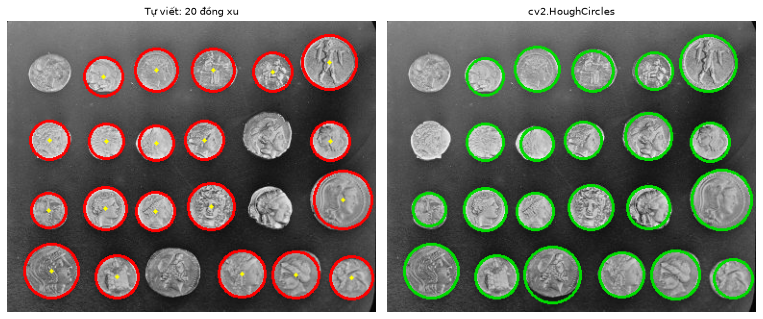

In [12]:
coins = img_as_ubyte(data.coins())
coin_edges = cv2.Canny(cv2.GaussianBlur(coins, (5, 5), 1.2), 50, 120)
t0 = time.perf_counter(); circles = s9.hough_circles(coin_edges, coins, radii=range(18, 31, 2), n_peaks=40, rel_thresh=0.55); t_c = time.perf_counter() - t0
cv_c = cv2.HoughCircles(cv2.GaussianBlur(coins, (5, 5), 1.2), cv2.HOUGH_GRADIENT, dp=1, minDist=30, param1=120, param2=30, minRadius=16, maxRadius=32)
vis = cv2.cvtColor(coins, cv2.COLOR_GRAY2RGB); vis2 = vis.copy()
for x, y, r, v in circles: cv2.circle(vis, (x, y), r, (255, 0, 0), 2); cv2.circle(vis, (x, y), 2, (255, 255, 0), -1)
if cv_c is not None:
    for x, y, r in np.round(cv_c[0]).astype(int): cv2.circle(vis2, (x, y), r, (0, 220, 0), 2)
print(f"Hough tròn tự viết (gradient voting): {len(circles)} vòng tròn trong {t_c * 1000:.0f} ms | cv2.HoughCircles: {0 if cv_c is None else len(cv_c[0])}")
if cv_c is not None and len(circles):
    d = np.linalg.norm(np.array([[c[0], c[1]] for c in circles])[:, None] - cv_c[0][None, :, :2], axis=2).min(axis=1)
    print(f"Tâm tự viết nằm trong 6 px so với một tâm của cv2: {(d < 6).mean() * 100:.0f}%")
show([vis, vis2], [f"Tự viết: {len(circles)} đồng xu", "cv2.HoughCircles"], size=5.5)

### 3.2.5 Góc: Harris và Shi-Tomasi (Chap 08 s.14–33)

Góc là điểm mà cả hai trị riêng của ma trận cấu trúc $H$ đều lớn: **Harris** dùng $R=\det H-k\,\mathrm{tr}^2H$, **Shi-Tomasi** dùng thẳng trị riêng nhỏ $\lambda_-$ (đúng "feature scoring function" ở s.24).

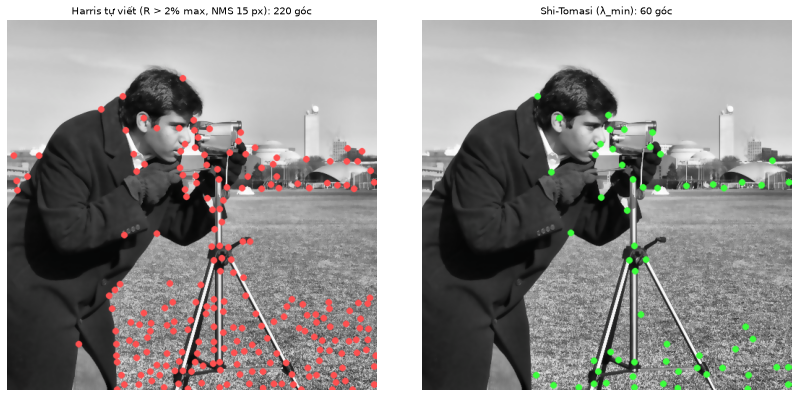

82% góc Shi-Tomasi có góc Harris trong 5 px (hai điểm số đo gần như cùng một thứ)


In [13]:
Rh, lam = s58.harris_response(pre["gray"])
pts_h = s58.local_maxima(Rh, 0.02, 15)
pts_st = geo.detect_corners(pre["gray"])
def mark(img, pts, color):
    o = img.copy()
    for x, y in pts: cv2.circle(o, (int(x), int(y)), 4, color, -1, cv2.LINE_AA)
    return o
show([mark(pre["denoised"], pts_h, (255, 80, 80)), mark(pre["denoised"], pts_st, (60, 255, 60))],
     [f"Harris tự viết (R > 2% max, NMS 15 px): {len(pts_h)} góc", f"Shi-Tomasi (λ_min): {len(pts_st)} góc"], size=6)
d = np.linalg.norm(pts_st[:, None, :] - pts_h[None, :, :], axis=2).min(axis=1)
print(f"{(d < 5).mean() * 100:.0f}% góc Shi-Tomasi có góc Harris trong 5 px (hai điểm số đo gần như cùng một thứ)")

### 3.2.6 Ước lượng phép biến đổi hình học giữa hai ảnh cùng cảnh (Chap 04 s.27–36; Chap 08)

Hướng "ước lượng affine/projective" của đề: coi ảnh thứ hai là cảnh bị đổi góc nhìn (homography đã biết, $+$ nhiễu và lệch sáng), tìm lại phép biến đổi bằng **SIFT → ratio test → RANSAC**, và so với homography thật. Đồng thời xem một mô hình **affine** (6 DoF) giải thích được bao nhiêu so với **homography** (8 DoF) khi phép biến đổi thật có thành phần phối cảnh.

SIFT: 1403/1452 điểm, 495 khớp sau ratio test, 472 inlier RANSAC
Sai số căn chỉnh (trung bình 4 góc + tâm, px): homography = 0.23 | affine (cùng inlier) = 13.48
RMS sai số chiếu trên inlier: homography = 0.50 px | affine = 4.49 px


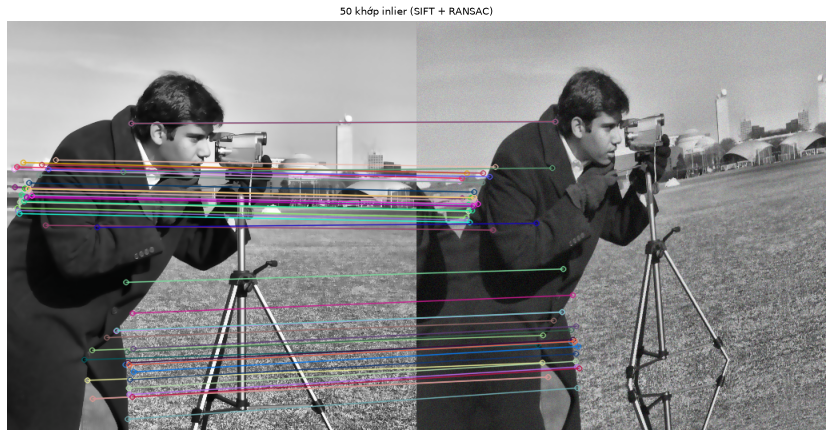

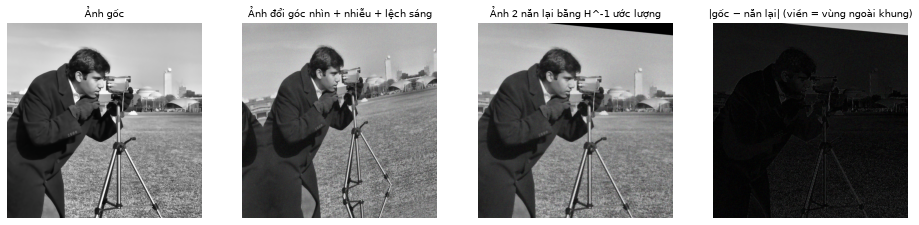

In [14]:
H_true = np.array([[0.92, 0.12, 25.0], [-0.10, 1.02, 18.0], [2.5e-4, 1.5e-4, 1.0]])
base = pre["denoised"]
view2 = cv2.warpPerspective(base, H_true, base.shape[1::-1], borderMode=cv2.BORDER_REFLECT)
view2 = add_gaussian_noise(np.clip(view2.astype(np.float32) * 0.85 + 12, 0, 255).astype(np.uint8), sigma=6)       # lệch sáng + nhiễu
sift = cv2.SIFT_create()
g1, g2 = cv2.cvtColor(base, cv2.COLOR_RGB2GRAY), cv2.cvtColor(view2, cv2.COLOR_RGB2GRAY)
k1, d1 = sift.detectAndCompute(g1, None); k2, d2 = sift.detectAndCompute(g2, None)
i1, i2, _, _ = s58.match_ratio_test(d1, d2, 0.75)
p1, p2 = np.float32([k1[i].pt for i in i1]), np.float32([k2[j].pt for j in i2])
H_est, inl = sl.ransac_homography(p1, p2, thresh=3.0)
A_est = sl.fit_affine(p1[inl], p2[inl])
W_, Hh = base.shape[1], base.shape[0]
print(f"SIFT: {len(k1)}/{len(k2)} điểm, {len(i1)} khớp sau ratio test, {int(inl.sum())} inlier RANSAC")
print(f"Sai số căn chỉnh (trung bình 4 góc + tâm, px): homography = {s58.corner_transfer_error(H_est, H_true, W_, Hh):.2f} | affine (cùng inlier) = {s58.corner_transfer_error(A_est, H_true, W_, Hh):.2f}")
res_h = np.linalg.norm(sl.apply_homography(H_est, p1[inl]) - p2[inl], axis=1); res_a = np.linalg.norm(sl.apply_homography(A_est, p1[inl]) - p2[inl], axis=1)
print(f"RMS sai số chiếu trên inlier: homography = {np.sqrt((res_h ** 2).mean()):.2f} px | affine = {np.sqrt((res_a ** 2).mean()):.2f} px")
back = cv2.warpPerspective(view2, np.linalg.inv(H_est), base.shape[1::-1])
vis = cv2.drawMatches(base, k1, view2, k2, [cv2.DMatch(int(a), int(b), 0) for a, b in zip(i1[inl][:50], i2[inl][:50])], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show([vis], ["50 khớp inlier (SIFT + RANSAC)"], size=12)
show([base, view2, back, cv2.absdiff(base, back)], ["Ảnh gốc", "Ảnh đổi góc nhìn + nhiễu + lệch sáng", "Ảnh 2 nắn lại bằng H^-1 ước lượng", "|gốc − nắn lại| (viền = vùng ngoài khung)"], size=3.4)

**Nhận xét 3.2.**
- *Biên*: Canny cho nét **mảnh** (≈ 1.2 px) so với ngưỡng gradient thô (≈ 3.3 px) — đúng vai trò của non-maximum suppression. Nhưng Canny cũng **đứt đoạn hơn** (1103 thành phần liên thông so với 450) vì texture (cỏ) sinh vô số đoạn biên ngắn; **closing** r=2 nối được chúng (còn 23 thành phần) — quá tay: các vùng texture dính thành khối, tức mất thông tin; kích thước phần tử cấu trúc là đánh đổi cần chỉnh theo ảnh.
- *Hough đường thẳng*: bản tự viết cho đúng các góc như `cv2.HoughLines` (−45°, −28°, 0°) và chậm hơn chút (~25 ms so với ~10 ms; đã vector hóa theo θ bằng `np.bincount`). **Nhưng nhìn overlay**, phần lớn đỉnh mạnh nhất (cụm −45°) không bám chân máy: phép thử ảnh nhiễu thuần cho thấy đó là **thiên lệch độ dài dây cung** (đường chéo khung vuông), và 25 đoạn dài nhất của `HoughLinesP` cũng dồn vào cỏ phía dưới bên phải. Chia phiếu cho độ dài dây cung xóa thiên lệch (recall đường thật ở σ=40 tăng từ ≈ 0.25 lên ≈ 0.79), nhưng ảnh thật nhiều texture vẫn cần ngưỡng độ dài/liên tục hoặc loại vùng texture trước khi Hough. Phiếu của các đỉnh thật giảm còn ≈ 70% khi điểm biên bị dịch chỉ 1 px (đỉnh nhòe sang ô lân cận), còn clutter tăng số ứng viên giả có độ mạnh ngang đỉnh thật từ 30 lên 51 và 131 — đúng hai hiện tượng của slide 25–26. Đường Hough là *đường vô hạn* nên pipeline dùng `HoughLinesP` + top-K đoạn dài nhất để có điểm đầu/cuối; cảnh nhiều texture vẫn sinh nhiều đường giả.
- *Hough tròn bằng gradient*: rất nhanh (~15 ms) vì chỉ bỏ phiếu 2 ô/điểm; tìm 20 vòng tròn so với 22 của `cv2.HoughCircles`, 95% tâm trùng trong 6 px. Cần biết khoảng bán kính; đồng xu bị che hoặc có biên yếu dễ sót.
- *Góc*: Harris và Shi-Tomasi chọn gần cùng các điểm (82% trùng trong 5 px); góc chỉ đáng tin ở vùng có cấu trúc, texture cỏ tạo nhiều góc giả nên cần NMS và ngưỡng tương đối.
- *Ước lượng biến đổi*: dù ảnh thứ hai bị lệch sáng và nhiễu, SIFT + RANSAC giữ 472/495 khớp và phục hồi homography với sai số 0.23 px; mô hình **affine** trên cùng các inlier sai tới ≈ 13 px (RMS chiếu 4.5 px so với 0.5 px) vì phép biến đổi thật có thành phần phối cảnh mà affine không biểu diễn được. Hạn chế: homography chỉ đúng với cảnh phẳng hoặc camera xoay quanh tâm quang học.

---
## 3.3 — Phân tích nội dung / đối tượng

### 3.3.1 Vùng nổi bật (saliency) làm điểm khởi đầu

**Spectral residual** (Hou & Zhang 2007): trong phổ biên độ log của ảnh, phần "điển hình" là phần được làm mượt; **phần dư** (log-amplitude trừ trung bình cục bộ) chứa các thành phần bất thường, khôi phục bằng pha gốc + FFT ngược cho bản đồ nổi bật. Không cần huấn luyện. Từ bản đồ này tạo hình chữ nhật hạt giống cho GrabCut.

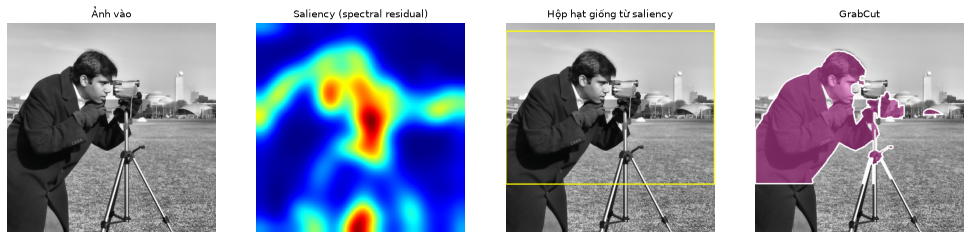

GrabCut: 3514 ms, tiền cảnh = 25.9% ảnh


In [15]:
saliency = content.spectral_residual_saliency(pre["gray"])
rect = content.saliency_to_bbox(saliency)
t0 = time.perf_counter(); mask_gc = content.segment_grabcut(pre["denoised"], rect); t_gc = time.perf_counter() - t0
sal_viz = cv2.cvtColor(cv2.applyColorMap((saliency * 255).astype(np.uint8), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
rect_viz = pre["denoised"].copy(); x, y, w, h = rect; cv2.rectangle(rect_viz, (x, y), (x + w, y + h), (255, 255, 0), 2)
content_viz = content.draw_content_overlay(pre["denoised"], mask_gc)
show([pre["denoised"], sal_viz, rect_viz, content_viz], ["Ảnh vào", "Saliency (spectral residual)", "Hộp hạt giống từ saliency", "GrabCut"], size=3.6)
print(f"GrabCut: {t_gc * 1000:.0f} ms, tiền cảnh = {(mask_gc > 0).mean() * 100:.1f}% ảnh")

### 3.3.2 Các phương pháp phân vùng của slide, áp trên ảnh thật (Chap 10–11)

- **Ngưỡng** (s.4–10): Otsu (cực đại phương sai giữa hai lớp) và ngưỡng *thích nghi* (so với trung bình cục bộ — xử lý chiếu sáng không đều).
- **Region growing** (s.11–15): từ hạt giống, gộp lân cận có mức xám gần trung bình vùng.
- **K-means** (s.23–38): gom pixel theo $(R,G,B)$ hoặc $(R,G,B,x,y)$; phải **chuẩn hóa thang đo** để thuộc tính không bị lấn át.
- **Watershed** (s.16–22): "ngập" địa hình gradient; không marker thì **phân mảnh quá mức**, có marker thì chỉ các cực tiểu được chọn mới tạo lưu vực.
- **Graph cut / GrabCut** (s.39–58): gán nhãn pixel bằng cực tiểu hóa năng lượng $E(f)=\sum_p D_p(f_p)+\sum_{p,q}V(f_p,f_q)$ qua min-cut/max-flow; GrabCut dùng mô hình màu Gauss hỗn hợp cho $D_p$.

Ta cần một quy tắc **gán nhãn tiền cảnh** thống nhất cho các phương pháp không giám sát: *vùng có độ nổi bật trung bình cao nhất*.

Tổng thời gian 7 phương pháp: 6.5s
Watershed KHÔNG marker: 15501 vùng (phân mảnh quá mức) | có marker: 2 vùng


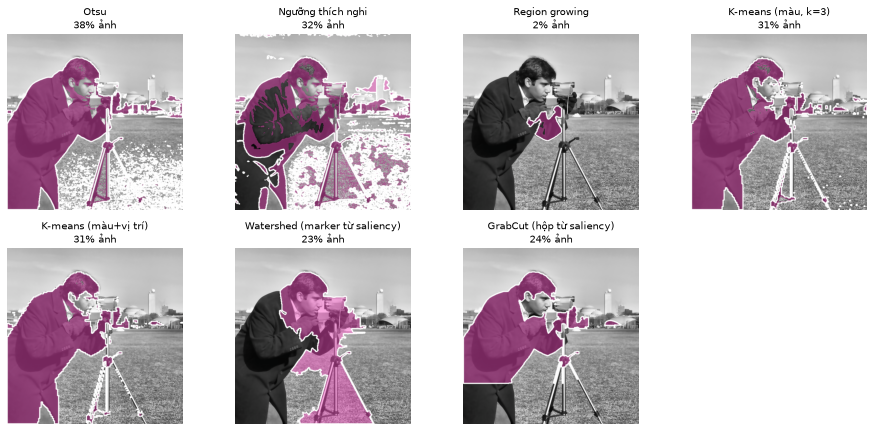


Độ đồng thuận với GrabCut (IoU) -- không phải độ chính xác, vì ảnh thật không có ground truth:
  Otsu                             IoU = 0.63
  Ngưỡng thích nghi                IoU = 0.32
  Region growing                   IoU = 0.08
  K-means (màu, k=3)               IoU = 0.71
  K-means (màu+vị trí)             IoU = 0.72
  Watershed (marker từ saliency)   IoU = 0.23
  GrabCut (hộp từ saliency)        IoU = 1.00


In [16]:
def pick_by_saliency(labels, sal):
    """Nhãn có saliency trung bình cao nhất -> mask 0/255."""
    ids = [i for i in np.unique(labels)]
    best = max(ids, key=lambda i: sal[labels == i].mean())
    return ((labels == best) * 255).astype(np.uint8)

def run_methods(rgb, pre_, sal, rect_):
    g_ = pre_["gray"]; out = {}
    t = s9.otsu_threshold(g_); out["Otsu"] = pick_by_saliency((g_ > t).astype(int), sal)
    out["Ngưỡng thích nghi"] = pick_by_saliency((s9.adaptive_threshold(g_, 51, 5) > 0).astype(int), sal)
    sy, sx = np.unravel_index(np.argmax(cv2.GaussianBlur(sal, (0, 0), 5)), sal.shape)
    out["Region growing"] = s9.region_growing(cv2.GaussianBlur(g_, (0, 0), 1.5), (int(sx), int(sy)), tol=18)
    out["K-means (màu, k=3)"] = pick_by_saliency(s9.kmeans_segment(pre_["denoised"], 3), sal)
    out["K-means (màu+vị trí)"] = pick_by_saliency(s9.kmeans_segment(pre_["denoised"], 3, True, 1.0), sal)
    fg = (sal > np.percentile(sal, 95)).astype(np.uint8) * 255; fg = s9.erode(fg, s9.disk(1))
    bg = ((sal < np.percentile(sal, 40)) * 255).astype(np.uint8)
    out["Watershed (marker từ saliency)"] = s9.watershed_markers(g_, fg, bg)
    out["GrabCut (hộp từ saliency)"] = content.segment_grabcut(pre_["denoised"], rect_)
    return out

t0 = time.perf_counter(); real = run_methods(scene, pre, saliency, rect); print(f"Tổng thời gian 7 phương pháp: {time.perf_counter() - t0:.1f}s")
ws_free = s9.watershed_no_markers(pre["gray"])
print(f"Watershed KHÔNG marker: {len(np.unique(ws_free))} vùng (phân mảnh quá mức) | có marker: 2 vùng")
show([content.draw_content_overlay(pre["denoised"], m) for m in real.values()], [f"{k}\n{(m > 0).mean() * 100:.0f}% ảnh" for k, m in real.items()], ncols=4, size=3.3)
ref = real["GrabCut (hộp từ saliency)"]
print("\nĐộ đồng thuận với GrabCut (IoU) -- không phải độ chính xác, vì ảnh thật không có ground truth:")
for k, m in real.items(): print(f"  {k:32s} IoU = {s9.iou(m, ref):.2f}")

### 3.3.3 Đánh giá có ground truth: 6 cảnh tổng hợp × 3 seed

Ảnh thật không có mask chuẩn, nên so sánh *khách quan* cần dữ liệu biết đáp án. Ta ghép một đối tượng có hình dạng thật (`skimage.data.horse()` — silhouette con ngựa, chiếm ~ 1/4 khung, lệch trái-dưới) với một ảnh nền khác, được mask chuẩn **từng pixel**. Có **6 cặp tiền cảnh/hậu cảnh** (3 cặp tương phản cao, 1 trung bình, 2 thấp) để kết quả không dựa vào một cảnh may rủi. Mỗi phương pháp chạy với **3 seed** (GrabCut và k-means khởi tạo ngẫu nhiên) ⇒ 18 lượt/phương pháp; báo cáo **trung bình ± độ lệch chuẩn** của IoU.

Phương pháp không giám sát phải chọn nhãn nào là tiền cảnh. Để tách *lỗi của thuật toán* khỏi *lỗi của quy tắc chọn nhãn*, mỗi phương pháp được báo cáo hai lần: **blind** (chọn nhãn có saliency trung bình cao nhất, như pipeline thật) và **oracle** (chọn nhãn có IoU cao nhất với ground truth — cận trên). Với GrabCut ta so ba loại hộp hạt giống: từ saliency, mặc định 80% giữa ảnh, và hộp lý tưởng (bao khít mask thật).

In [17]:
import tonghop_benchmark as bm
t0 = time.perf_counter(); table, per_scene, GT = bm.run_benchmark(seeds=(0, 1, 2), scale=0.6, grabcut_iters=5); print(f"Benchmark: {time.perf_counter() - t0:.0f}s")

print(f"{'phương pháp':34s} {'IoU TB ± std (18 lượt)':>24s}")
for m, (mu, sd) in sorted(table.items(), key=lambda kv: -kv[1][0]):
    print(f"{m:34s} {mu:14.2f} ± {sd:.2f}")

cols = ["K-means (màu)", "K-means (màu) (oracle)", "Watershed (marker từ saliency)", "GrabCut (hộp saliency)", "GrabCut (hộp 80% giữa ảnh)", "GrabCut (hộp lý tưởng)"]
short = ["kmeans", "kmeans*", "watershed", "GC-sal", "GC-80%", "GC-ideal"]
print("\nIoU trung bình theo từng cảnh (3 seed); * = oracle chọn nhãn")
print(f"{'cảnh':20s}" + "".join(f"{c:>11s}" for c in short))
for sc, d in per_scene.items():
    print(f"{sc:20s}" + "".join(f"{d[c]:11.2f}" for c in cols))

Benchmark: 58s
phương pháp                          IoU TB ± std (18 lượt)
GrabCut (hộp lý tưởng)                       0.70 ± 0.17
GrabCut (hộp 80% giữa ảnh)                   0.50 ± 0.23
K-means (màu) (oracle)                       0.45 ± 0.34
K-means (màu)                                0.43 ± 0.36
GrabCut (hộp saliency)                       0.41 ± 0.19
Watershed (marker từ saliency)               0.28 ± 0.23
K-means (màu+vị trí) (oracle)                0.27 ± 0.23
K-means (màu+vị trí)                         0.26 ± 0.24
Ngưỡng thích nghi (oracle)                   0.20 ± 0.09
Otsu (oracle)                                0.19 ± 0.14
Ngưỡng thích nghi                            0.17 ± 0.12
Otsu                                         0.11 ± 0.17

IoU trung bình theo từng cảnh (3 seed); * = oracle chọn nhãn
cảnh                     kmeans    kmeans*  watershed     GC-sal     GC-80%   GC-ideal
astronaut/sky              0.92       0.92       0.23       0.31       0.57       0.58
rocke

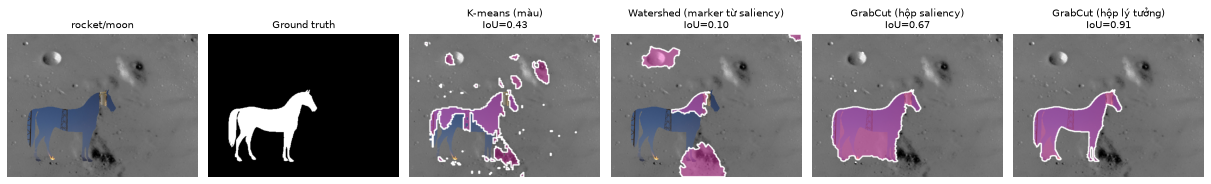

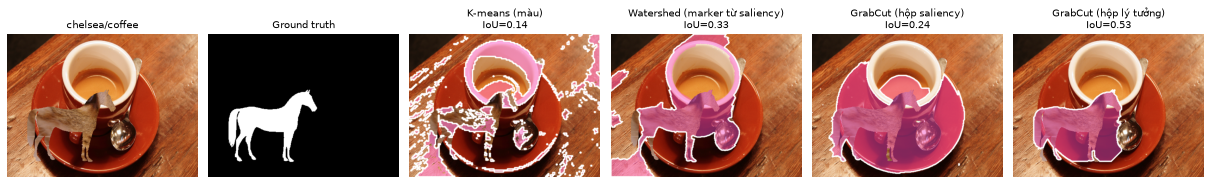

In [18]:
# Minh họa trực quan hai cảnh (seed 0): dễ nhất và khó nhất theo GrabCut hộp lý tưởng
catalog = bm.scene_catalog()
for sname in ("rocket/moon", "chelsea/coffee"):
    fg_, bg_, _ = catalog[sname]
    sc = bm.compose(fg_, bg_, GT); res = bm.run_scene(sc, GT, seed=0)
    names = ["K-means (màu)", "Watershed (marker từ saliency)", "GrabCut (hộp saliency)", "GrabCut (hộp lý tưởng)"]
    show([sc, to_gray3(GT)] + [content.draw_content_overlay(sc, res[n]) for n in names],
         [sname, "Ground truth"] + [f"{n}\nIoU={s9.iou(res[n], GT):.2f}" for n in names], ncols=6, size=2.9)

**Nhận xét 3.3 (đối chiếu số liệu ở các ô trên).**
- *Ảnh thật* (không có ground truth nên chỉ so sánh độ đồng thuận ở 3.3.2): k-means và Otsu cùng GrabCut tách ra người chụp ảnh; ngưỡng thích nghi bị texture cỏ làm vỡ; **region growing** chỉ phủ ~2% ảnh vì kết cấu vải/cỏ vi phạm giả định "mức xám gần trung bình vùng"; watershed **không marker** vỡ thành 15 501 vùng (over-segmentation đúng như slide).
- **Không phương pháp nào thắng ở mọi cảnh, và độ phân tán lớn.** K-means (màu) đạt IoU 0.88–0.92 ở hai cảnh nền trời (hai quần thể màu tách rõ) nhưng chỉ 0.04–0.43 ở bốn cảnh còn lại, nên trung bình 0.43 đi kèm std 0.36 — phân phối hai đỉnh, không phải "kết quả trung bình 0.43". Lưu ý std ở bảng gộp cả biến thiên giữa các cảnh lẫn giữa các seed nên **không phải khoảng tin cậy**; với 6 cảnh cắt-dán, chỉ nên đọc là xu hướng.
- **Lỗi nằm ở thuật toán, không phải ở quy tắc chọn nhãn.** Blind và oracle gần như trùng nhau (k-means 0.43 so với 0.45, Otsu 0.11 so với 0.19, chỉ cảnh `coffee/chelsea` lệch rõ: 0.04 so với 0.17). Ngay cả khi chọn nhãn *đúng nhất*, Otsu (0.19) và ngưỡng thích nghi (0.20) vẫn kém vì một ngưỡng mức xám không thể tách đối tượng có cả vùng sáng lẫn tối — một giới hạn của cách biểu diễn (chỉ xét mức xám), không phải của cách gán nhãn.
- **Hạt giống quyết định GrabCut.** Với hộp lý tưởng GrabCut đạt 0.70 ± 0.17 (cao nhất bảng); hộp mặc định 80% giữa ảnh 0.50; hộp từ saliency 0.41 ± 0.19. Hộp saliency **thua hộp mặc định về trung bình**: nó nhỉnh hơn ở 2/6 cảnh (`coffee/chelsea`, `chelsea/coffee`, chỉ +0.07 và +0.04), hòa ở `astronaut/coffee` (−0.01) và thua ở ba cảnh còn lại, tới −0.31 (`chelsea/sky` −0.31, `astronaut/sky` −0.26, `rocket/moon` −0.08: hộp quá lớn hoặc lệch nên GrabCut gộp cả vùng nền). Spectral-residual saliency chỉ phản ứng với biên/vùng bất thường nên không bảo đảm bao khít đối tượng; hướng cải thiện là co hộp bằng ngưỡng saliency chặt hơn hoặc dùng GrabCut hai pha (mask → hạt giống chắc chắn).
- **Cận trên vẫn thấp (~0.7).** Silhouette ngựa mảnh/lõm (chân) và mô hình màu GMM lẫn giữa tiền/hậu cảnh khi màu chồng lấn (`astronaut/coffee`, `chelsea/coffee`: 0.53) khiến ngay cả hộp hoàn hảo cũng không vượt ~0.55 ở cảnh khó; riêng `coffee/chelsea` đạt 0.95 do tiền cảnh khác nền hẳn về kết cấu/màu.
- *Giới hạn thí nghiệm*: đối tượng cắt-dán nên viền không có chuyển tiếp tự nhiên (không mờ, không bóng đổ), chỉ một hình dạng và một kích thước, 6 cặp ảnh; kết quả chưa khái quát cho ảnh thật nhiều đối tượng. Phần "học sâu" (Chap 12–13: CNN/R-CNN/YOLO với trọng số huấn luyện sẵn) là hướng phù hợp khi cần nhận dạng *loại* đối tượng hoặc nhiều đối tượng, nhưng không chạy ở đây vì môi trường offline.

---
## 3.4 — Trực quan hóa và so sánh trước/sau

Đề yêu cầu hiển thị *bounding box, mask, keypoint, đường thẳng, mặt phẳng...* và so sánh đầu vào/đầu ra. Một khung tổng hợp trên cảnh thật, cùng bảng thời gian từng bước (mở rộng "tối ưu tốc độ").

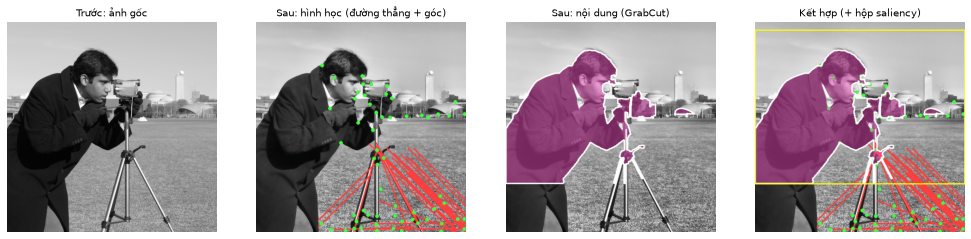

bước                                         ms
3.1 Tiền xử lý (CLAHE + bilateral)         16.7
3.2 Canny                                   1.3
3.2 HoughLinesP (OpenCV)                   11.8
3.2 Hough đường (tự viết)                  24.6
3.2 Shi-Tomasi                              4.4
3.3 Saliency                                1.7
3.3 GrabCut (8 vòng)                     3252.9
Tổng                                     3288.9   (không tính bản Hough tự viết)



cấu hình GrabCut                     ms    IoU so với 8 vòng @ 512px


8 vòng, ảnh x1.0                   4674                         0.45


3 vòng, ảnh x1.0                   2129                         0.93


1 vòng, ảnh x1.0                   1905                         0.57


3 vòng, ảnh x0.5                    370                         0.85
1 vòng, ảnh x0.5                    181                         0.56


In [19]:
# Một ảnh tổng hợp: đường thẳng Hough + góc Shi-Tomasi + hộp saliency + viền GrabCut
geometry_viz = geo.draw_geometry(pre["denoised"], lines, pts_st)
combined = content.draw_content_overlay(geometry_viz, mask_gc)
cv2.rectangle(combined, (x, y), (x + w, y + h), (255, 255, 0), 2)
show([scene, geometry_viz, content_viz, combined],
     ["Trước: ảnh gốc", "Sau: hình học (đường thẳng + góc)", "Sau: nội dung (GrabCut)", "Kết hợp (+ hộp saliency)"], size=3.6)

timing = {}
t = time.perf_counter(); p_ = prep.preprocess(scene); timing["3.1 Tiền xử lý (CLAHE + bilateral)"] = time.perf_counter() - t
t = time.perf_counter(); e_ = geo.detect_edges(p_["gray"]); timing["3.2 Canny"] = time.perf_counter() - t
t = time.perf_counter(); geo.detect_lines(e_); timing["3.2 HoughLinesP (OpenCV)"] = time.perf_counter() - t
t = time.perf_counter(); s9.hough_lines_accumulator(e_); timing["3.2 Hough đường (tự viết)"] = time.perf_counter() - t
t = time.perf_counter(); geo.detect_corners(p_["gray"]); timing["3.2 Shi-Tomasi"] = time.perf_counter() - t
t = time.perf_counter(); s_ = content.spectral_residual_saliency(p_["gray"]); timing["3.3 Saliency"] = time.perf_counter() - t
t = time.perf_counter(); content.segment_grabcut(p_["denoised"], content.saliency_to_bbox(s_)); timing["3.3 GrabCut (8 vòng)"] = time.perf_counter() - t
print(f"{'bước':38s} {'ms':>8s}")
for k, v in timing.items(): print(f"{k:38s} {v * 1000:8.1f}")
print(f"{'Tổng':38s} {sum(timing.values()) * 1000 - timing['3.2 Hough đường (tự viết)'] * 1000:8.1f}   (không tính bản Hough tự viết)")

# Mở rộng "tối ưu tốc độ": GrabCut chiếm gần toàn bộ thời gian -> thử giảm số vòng lặp và/hoặc kích thước ảnh
ref_mask = content.segment_grabcut(p_["denoised"], content.saliency_to_bbox(s_), iterations=8)
print(f"\n{'cấu hình GrabCut':30s} {'ms':>8s} {'IoU so với 8 vòng @ 512px':>28s}")
for iters, scale in [(8, 1.0), (3, 1.0), (1, 1.0), (3, 0.5), (1, 0.5)]:
    small = cv2.resize(p_["denoised"], None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    rect_s = tuple(int(v * scale) for v in content.saliency_to_bbox(s_))
    t = time.perf_counter(); m_ = content.segment_grabcut(small, rect_s, iterations=iters); dt = time.perf_counter() - t
    m_ = cv2.resize(m_, ref_mask.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"{iters} vòng, ảnh x{scale:<4}              {dt * 1000:8.0f} {s9.iou(m_, ref_mask):28.2f}")

---
## Tổng kết

| Mục | Kỹ thuật (slide) | Kết luận rút ra từ số liệu |
|---|---|---|
| 3.1 | CLAHE, bilateral (Chap 01–02) | CLAHE nâng tương phản cục bộ nhiều nhất nhưng vẫn khuếch đại nhiễu vùng phẳng; **bilateral** cho PSNR và F1 biên cao nhất, Gaussian/median mất ~2/3 biên thật |
| 3.2 | Canny, morphology, Hough, Harris, SIFT+RANSAC (Chap 03, 04, 06–09) | Hough tự viết khớp OpenCV về góc và nhạy với jitter/clutter đúng như slide; homography phục hồi với sai số 0.23 px, affine ≈ 13 px khi có phối cảnh |
| 3.3 | Otsu, k-means, watershed, GrabCut (Chap 10–11) | Không phương pháp nào thắng mọi cảnh; k-means thắng khi màu tách rõ, mọi phương pháp tụt khi màu chồng lấn; khâu yếu là hộp hạt giống từ saliency chứ không phải GrabCut |
| 3.4 | Overlay, trước/sau, thời gian | GrabCut chiếm ≈ 99% thời gian pipeline (~3.7 s cho ảnh 512 px); giảm một nửa kích thước ảnh cắt xuống ~0.4 s (IoU 0.84 so với bản đầy đủ), còn giảm số vòng lặp tiết kiệm ít vì thời gian chủ yếu ở khởi tạo GMM/dựng đồ thị |

Hình của script `python src/tonghop_pipeline.py` vẫn được lưu ở `outputs/tonghop_scene/`; xem `report/REPORT_TEMPLATE_TONGHOP.md` cho bản viết báo cáo (phân công thành viên theo yêu cầu của đề cần được nhóm điền).